# Pjesa I · 1/2: Kuptimi dhe kualiteti i të dhënave

**Pyetja e analizës:** Si ndryshon çmimi për natë i listimeve Airbnb në Londër sipas llojit të dhomës, lagjes dhe kapacitetit?

Një rresht përfaqëson një listim. Burimi i deklaruar i projektit është **Inside Airbnb, London listings**; skedari lokal është `dataset/listings.csv.gz`. Kontrolloni datën/versionin e shkarkimit në burimin tuaj para dorëzimit. Ky notebook **nuk ndryshon dataset-in origjinal**.

**Rrjedha:** mbledhja → tipet → kualiteti → mungesat → dublikatat → agregimi → mostrimi. Notebook-u 02 vazhdon me pastrimin dhe transformimet.

In [3]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings.csv.gz").is_file() and (ROOT.parent / "dataset" / "listings.csv.gz").is_file():
    ROOT = ROOT.parent
DATA_PATH = Path(os.environ.get("PVDH_DATASET_PATH", ROOT / "dataset" / "listings.csv.gz"))
assert DATA_PATH.is_file(), f"Dataset-i nuk u gjet: {DATA_PATH}"
raw = pd.read_csv(DATA_PATH, low_memory=False, dtype={"host_profile_id": "string"})
print(f"Burimi: {DATA_PATH.name} | Rreshta: {len(raw):,} | Kolona: {raw.shape[1]}")
raw.head(3)[["id", "name", "neighbourhood_cleansed", "room_type", "price"]]

Burimi: listings.csv.gz | Rreshta: 91,954 | Kolona: 90


,id,name,neighbourhood_cleansed,room_type,price
0,11551,Artistic London Pied-à-Terre,Lambeth,Entire home/apt,$267.50
1,13913,Holiday London DB Room Let-on going,Islington,Private room,$127.00
2,15400,Bright Chelsea Apartment. Chelsea!,Kensington and Chelsea,Entire home/apt,$137.50


## 1. Tipet e të dhënave

`id` është identifikues, jo madhësi për llogaritje. `price` lexohet si tekst sepse përmban simbol monedhe dhe presje. Datat si `last_scraped` lexohen fillimisht si tekst. Kolonat `t/f` janë vlera logjike të koduara si tekst. Numërojmë tipet siç janë lexuar dhe shohim kolonat kryesore.

In [5]:
print(raw.dtypes.astype(str).value_counts().to_string())
display(raw[["id", "price", "last_scraped", "room_type", "host_is_superhost", "bedrooms"]].dtypes.to_frame("tipi fillestar"))

float64    42
object     28
int64      19
string      1


,tipi fillestar
id,int64
price,object
last_scraped,object
room_type,object
host_is_superhost,object
bedrooms,float64


## 2. Kualiteti dhe vlerat që mungojnë

Vlerat boshe nuk kanë gjithmonë të njëjtin kuptim. Një listim pa komente s'ka rezultat vlerësimi; kjo është mungesë e pritshme. Çmimi bosh është problem për analizën e çmimit. Kolonat 100% boshe nuk japin informacion. Grafiku tregon përqindjen e mungesave për kolonat më problematike.

,mungojnë,%
neighborhood_overview,91954,100.00
host_since,91954,100.00
host_response_time,91954,100.00
host_thumbnail_url,91954,100.00
host_acceptance_rate,91954,100.00
host_response_rate,91954,100.00
host_verifications,91954,100.00
neighbourhood,91954,100.00
host_total_listings_count,91954,100.00
host_neighbourhood,91954,100.00


Qeliza boshe: 1,933,263 / 8,275,860 (23.36%)
Kolona krejt bosh: 15


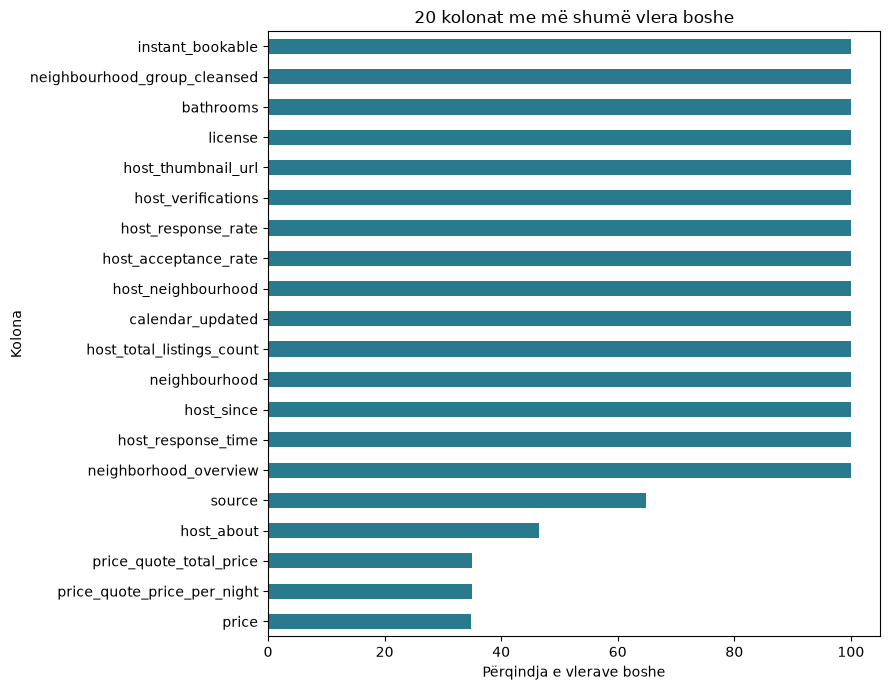

In [6]:
missing = raw.isna().sum().sort_values(ascending=False)
quality = pd.DataFrame({"mungojnë": missing, "%": (missing / len(raw) * 100).round(2)})
display(quality.head(25))
print(f"Qeliza boshe: {int(missing.sum()):,} / {raw.size:,} ({missing.sum()/raw.size:.2%})")
print(f"Kolona krejt bosh: {int(missing.eq(len(raw)).sum())}")
ax = quality.head(20)["%"].sort_values().plot.barh(figsize=(9, 7), color="#287a8c")
ax.set(xlabel="Përqindja e vlerave boshe", ylabel="Kolona", title="20 kolonat me më shumë vlera boshe")
plt.tight_layout()
plt.show()

## 3. Dublikatat dhe vlerat e dyshimta

Krahasojmë rreshta identikë dhe ID të përsëritura. Pastaj kontrollojmë kufijtë logjikë për kapacitetin dhe disponueshmërinë. Kufijtë e tillë duhen verifikuar sipas kuptimit të kolonës, jo vetëm statistikisht.

In [7]:
checks = pd.Series({
    "rreshta identikë": int(raw.duplicated().sum()),
    "ID të dyfishuara": int(raw["id"].duplicated().sum()),
    "kapacitet <= 0": int(raw["accommodates"].le(0).sum()),
    "availability_365 jashtë 0–365": int((~raw["availability_365"].between(0, 365)).sum()),
    "çmim bosh": int(raw["price"].isna().sum()),
})
display(checks.to_frame("numri"))

,numri
rreshta identikë,0
ID të dyfishuara,0
kapacitet <= 0,0
availability_365 jashtë 0–365,0
çmim bosh,32049


## 4. Integrimi, agregimi dhe mostrimi

**Integrimi:** projekti ka një tabelë, prandaj nuk ka bashkim me një dataset tjetër. Nëse më vonë shtohen të dhëna kalendari ose komentesh, lidhja duhet të bëhet me ID-në e listimit.

**Agregimi:** përmbledhim çmimin sipas llojit të dhomës. Kjo është pamje eksploruese; pastrimi i plotë bëhet në notebook-un 02.

**Mostrimi:** zgjedhim 10% brenda secilit `room_type` që të ruajmë afërsisht përbërjen e kategorive. Për rezultatet përfundimtare përdorim tërë dataset-in e pastruar.

,count,median,mean
room_type,,,
Entire home/apt,40521,227.0,308.5
Hotel room,134,187.5,263.24
Private room,19085,80.0,122.05
Shared room,165,36.0,74.32


Madhësia e mostrës: 9,195


,të gjitha %,mostra %
room_type,,
Entire home/apt,66.42,66.42
Private room,33.14,33.14
Hotel room,0.23,0.23
Shared room,0.22,0.22


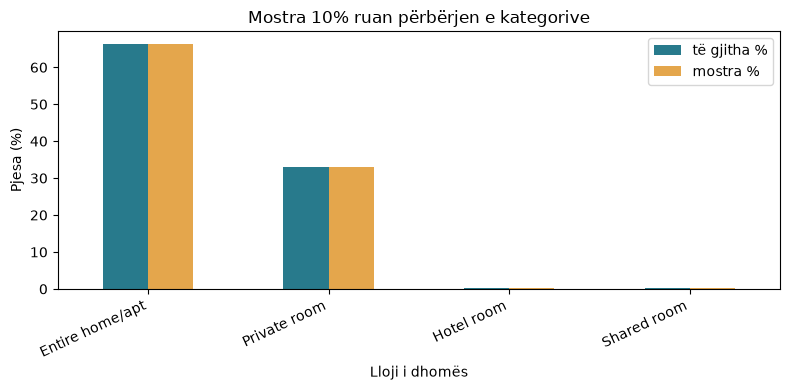

In [8]:
preview = raw[["room_type", "price"]].copy()
preview["price"] = pd.to_numeric(preview["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
display(preview.groupby("room_type", dropna=False)["price"].agg(["count", "median", "mean"]).round(2))
sample = raw.groupby("room_type", dropna=False, group_keys=False).sample(frac=0.10, random_state=42)
shares = pd.DataFrame({"të gjitha %": raw["room_type"].value_counts(normalize=True).mul(100),
                       "mostra %": sample["room_type"].value_counts(normalize=True).mul(100)}).round(2)
print(f"Madhësia e mostrës: {len(sample):,}")
display(shares)
ax = shares.plot.bar(figsize=(8, 4), color=["#287a8c", "#e4a64c"])
ax.set(xlabel="Lloji i dhomës", ylabel="Pjesa (%)", title="Mostra 10% ruan përbërjen e kategorive")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

**Përfundim:** mbani shënim numrin e rreshtave, kolonave, mungesave dhe dublikatave nga ekzekutimi juaj. Notebook-u tjetër dokumenton çdo vendim pastrimi dhe krahason gjendjen para/pas.